In [1]:
import glob, json, re
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for f in sorted(glob.glob("../logs-reels/raw/cowrie.json*")):
    for l in open(f):
        if l.strip():
            rows.append(json.loads(l))
cw = pd.DataFrame(rows)
cw["timestamp"] = pd.to_datetime(cw["timestamp"], utc=True)
cw = cw.drop_duplicates(subset=["session", "eventid", "timestamp"])
print(cw.shape, cw["timestamp"].min(), cw["timestamp"].max())
cw["eventid"].value_counts()

(574, 39) 2026-11-11 23:34:08.130527+00:00 2026-11-24 17:10:01.753990+00:00


eventid
cowrie.session.connect          122
cowrie.session.closed           121
cowrie.login.failed              64
cowrie.telnet.option             63
cowrie.client.version            50
cowrie.client.kex                50
cowrie.command.input             30
cowrie.login.success             21
cowrie.client.size               11
cowrie.session.params            11
cowrie.log.closed                11
cowrie.client.var                 6
cowrie.telnet.error               5
cowrie.command.failed             5
cowrie.session.file_download      4
Name: count, dtype: int64

In [2]:
oc_rows = []
for l in open("../logs-reels/raw/opencanary.log"):
    if not l.strip(): continue
    d = json.loads(l)
    if d["logtype"] == 1001: continue
    oc_rows.append({"timestamp": pd.to_datetime(d["utc_time"], utc=True),
                    "src_ip": d["src_host"], "dst_port": d["dst_port"],
                    "logtype": d["logtype"],
                    "username": d["logdata"].get("USERNAME"),
                    "password": d["logdata"].get("PASSWORD")})
oc = pd.DataFrame(oc_rows)
oc["service"] = oc["dst_port"].map({21:"FTP", 80:"HTTP", 3306:"MySQL"}).fillna("autre")
oc.groupby(["src_ip", "service"]).size()

src_ip        service
127.0.0.1     FTP         1
              HTTP        2
172.20.10.2   FTP        12
              MySQL      12
172.20.10.5   FTP        12
              MySQL      12
192.168.56.1  FTP         2
              HTTP        2
dtype: int64

In [3]:
sondes = cw[(cw["eventid"] == "cowrie.login.failed") &
            (cw["username"].str.contains(r"HTTP/|sip:|SIP/|^Call-ID|^Via:|^CSeq", na=False) |
             cw["password"].str.contains(r"HTTP/|sip:|SIP/|^Call-ID|^Via:|^CSeq", na=False))]
print(len(sondes), "événements ressemblant à des sondes de scan")
sondes[["src_ip", "dst_port", "username"]].head(10)

26 événements ressemblant à des sondes de scan


,src_ip,dst_port,username
18,172.20.10.5,2223,GET / HTTP/1.0
25,172.20.10.5,2223,OPTIONS sip:nm SIP/2.0
26,172.20.10.5,2223,From: <sip:nm@nm>;tag=root
27,172.20.10.5,2223,Call-ID: 50000
29,172.20.10.5,2223,Contact: <sip:nm@nm>
234,192.168.56.1,2223,GET / HTTP/1.0
267,192.168.56.1,2223,GET / HTTP/1.0
274,192.168.56.1,2223,OPTIONS sip:nm SIP/2.0
275,192.168.56.1,2223,From: <sip:nm@nm>;tag=root
276,192.168.56.1,2223,Call-ID: 50000


In [4]:
motif = r"HTTP/|sip:|SIP/|^Call-ID|^Via:|^CSeq|^Contact:|^From:|^To:|^Max-Forwards|^Accept:|^Content-Length"
est_sonde = (cw["username"].fillna("").str.contains(motif) |
             cw["password"].fillna("").str.contains(motif))

tent = cw[cw["eventid"].isin(["cowrie.login.failed", "cowrie.login.success"])].copy()
tent["sonde"] = est_sonde.loc[tent.index]
vraies = tent[~tent["sonde"]]

print("Tentatives totales :", len(tent))
print("Sondes de scan     :", tent["sonde"].sum())
print("Vraies tentatives  :", len(vraies))
print("  échecs :", (vraies["eventid"] == "cowrie.login.failed").sum())
print("  succès :", (vraies["eventid"] == "cowrie.login.success").sum())

Tentatives totales : 85
Sondes de scan     : 31
Vraies tentatives  : 54
  échecs : 33
  succès : 21


Top utilisateurs :
 username
root      25
admin      8
ubuntu     8
           7
alae       6
Name: count, dtype: int64 

Top mots de passe :
 password
123456                             15
                                    7
password                            7
ubuntu                              6
admin                               6
alae                                5
allo                                3
\xc3\xa0H\xc3\xa0H\xc3\xa0Halae     1
kali                                1
coucoucnje                          1
Name: count, dtype: int64 

Top couples :
 root:123456       11
:                  7
alae:alae          5
root:password      3
root:allo          3
root:ubuntu        2
root:admin         2
admin:123456       2
admin:password     2
admin:admin        2
Name: count, dtype: int64


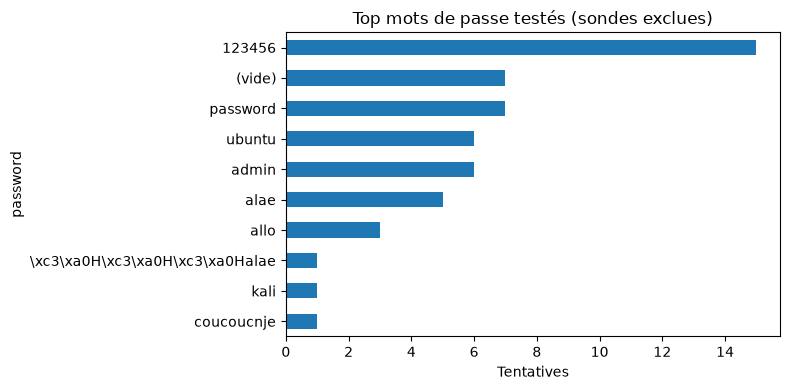

In [5]:
print("Top utilisateurs :\n", vraies["username"].value_counts().head(10), "\n")
print("Top mots de passe :\n", vraies["password"].value_counts().head(10), "\n")
print("Top couples :\n", (vraies["username"] + ":" + vraies["password"]).value_counts().head(10))

top = vraies["password"].replace("", "(vide)").value_counts().head(10)
plt.figure(figsize=(8, 4))
top.plot(kind="barh"); plt.gca().invert_yaxis()
plt.title("Top mots de passe testés (sondes exclues)")
plt.xlabel("Tentatives"); plt.tight_layout()
plt.savefig("../graphiques/top-mots-de-passe-reel.png", dpi=150)
plt.show()

src_ip
172.20.10.2     20
192.168.56.1    17
172.20.10.5     16
172.20.10.3      1
dtype: int64 

protocol
ssh       47
telnet     7
dtype: int64 

jour
2026-11-11    10
2026-11-12     1
2026-11-13     6
2026-11-18    17
2026-11-20     1
2026-11-24    19
dtype: int64


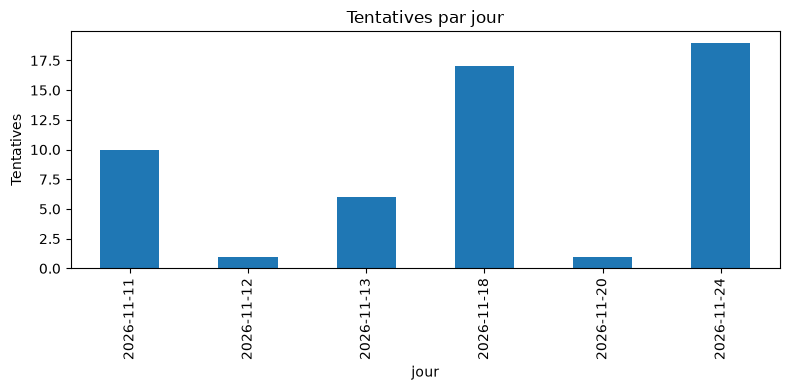

In [6]:
vraies = vraies.assign(jour=vraies["timestamp"].dt.date, heure=vraies["timestamp"].dt.hour)

print(vraies.groupby("src_ip").size().sort_values(ascending=False), "\n")
print(vraies.groupby(["protocol"]).size(), "\n")
print(vraies.groupby("jour").size())

vraies.groupby("jour").size().plot(kind="bar", figsize=(8, 4), title="Tentatives par jour")
plt.ylabel("Tentatives"); plt.tight_layout()
plt.savefig("../graphiques/tentatives-par-jour.png", dpi=150); plt.show()

In [7]:
profil = (cw.groupby("src_ip")
            .agg(sessions=("session", "nunique"),
                 echecs=("eventid", lambda s: (s == "cowrie.login.failed").sum()),
                 succes=("eventid", lambda s: (s == "cowrie.login.success").sum()),
                 commandes=("eventid", lambda s: (s == "cowrie.command.input").sum()),
                 premier=("timestamp", "min"), dernier=("timestamp", "max"))
            .sort_values("sessions", ascending=False))
profil

,sessions,echecs,succes,commandes,premier,dernier
src_ip,,,,,,
172.20.10.2,46,25,7,8,2026-11-18 12:21:48.765232+00:00,2026-11-24 16:51:08.420294+00:00
192.168.56.1,42,24,6,11,2026-11-11 23:34:08.130527+00:00,2026-11-13 11:34:41.492730+00:00
172.20.10.5,26,15,7,11,2026-11-24 16:49:16.898315+00:00,2026-11-24 17:10:01.753990+00:00
172.20.10.6,6,0,0,0,2026-11-18 12:45:52.304627+00:00,2026-11-20 15:03:05.035245+00:00
172.20.10.3,2,0,1,0,2026-11-18 12:11:11.108029+00:00,2026-11-18 12:21:48.625037+00:00


In [8]:
regles = [
    (r"\buname\b|/proc/cpuinfo|\blscpu\b|\bhostname\b|/etc/os-release", "Reconnaissance système",   "T1082"),
    (r"\bwhoami\b|(^|[;&| ])(id|who|w|users)(\s|$)", "Découverte utilisateur", "T1033"),
    (r"/etc/passwd|/etc/shadow|\bcat /etc/",                            "Découverte de comptes",    "T1087.001"),
    (r"\bps\b|\btop\b",                                                 "Découverte de processus",  "T1057"),
    (r"wget|curl|tftp|ftpget",                                          "Téléchargement de charge", "T1105"),
    (r"chmod \+x|(^|[;&| ])\./\S|(^|[;&| ])(ba)?sh\s", "Exécution de script", "T1059.004"),
    (r"crontab|authorized_keys|\.ssh",                                  "Persistance",              "T1053 / T1098"),
    (r"rm -rf|history -c|unset HISTFILE",                               "Effacement de traces",     "T1070"),
    (r"xmrig|minerd|stratum|cpuminer",                                  "Minage de crypto",         "T1496"),
]
def classer(c): return [(i, t) for m, i, t in regles if re.search(m, c)]

cmds = cw[cw["eventid"] == "cowrie.command.input"].copy()
cmds["classification"] = cmds["input"].apply(classer)

print("NON CLASSÉES :")
print(cmds[cmds["classification"].str.len() == 0]["input"].value_counts())

detail = cmds.explode("classification").dropna(subset=["classification"])
detail["intention"] = detail["classification"].str[0]
detail["technique"] = detail["classification"].str[1]
synthese = (detail.groupby(["intention", "technique"]).size()
            .reset_index(name="occurrences").sort_values("occurrences", ascending=False))
synthese

NON CLASSÉES :
input
exit                                                                                               4
                                                                                                   2
nmap -sV -p 21,22,23,80,2222,22022 192.168.56.102                                                  2
whoaim                                                                                             1
hydra -L users.txt -P passwords.txt -s 2223 telnet://172.20.10.6 -t 1 -w 10 -o hydra_telnet.log    1
EXIT                                                                                               1
ssh -p 22022 alae@192.168.56.102                                                                   1
sudo apt install nmap                                                                              1
hydra -R                                                                                           1
Name: count, dtype: int64


,intention,technique,occurrences
0,Découverte de comptes,T1087.001,4
4,Téléchargement de charge,T1105,4
3,Reconnaissance système,T1082,4
2,Découverte utilisateur,T1033,2
1,Découverte de processus,T1057,2


In [9]:
dl = cw[cw["eventid"] == "cowrie.session.file_download"][["timestamp", "src_ip", "url", "shasum"]]
print(dl.to_string())
print("\nHash uniques :", dl["shasum"].nunique())

                           timestamp       src_ip                         url                                                            shasum
122 2026-11-24 16:52:58.815294+00:00  172.20.10.5  http://example.com/test.sh  25ddf2c883e0d1958ea971d279a7e4f0fd446724ee3db7db19dadabd4a62e484
124 2026-11-24 16:53:16.106966+00:00  172.20.10.5  http://example.com/test.sh  25ddf2c883e0d1958ea971d279a7e4f0fd446724ee3db7db19dadabd4a62e484
506 2026-11-18 12:35:28.946648+00:00  172.20.10.2  http://example.com/test.sh  25ddf2c883e0d1958ea971d279a7e4f0fd446724ee3db7db19dadabd4a62e484
508 2026-11-18 12:35:44.129270+00:00  172.20.10.2  http://example.com/test.sh  25ddf2c883e0d1958ea971d279a7e4f0fd446724ee3db7db19dadabd4a62e484

Hash uniques : 1


In [10]:
synthese.to_csv("../preuves/synthese-mitre-reel.csv", index=False)
detail[["session","src_ip","timestamp","input","intention","technique"]].to_csv(
    "../preuves/commandes-classees-reel.csv", index=False)
profil.to_csv("../preuves/profil-ip-reel.csv")
vraies[["timestamp","src_ip","protocol","dst_port","username","password","eventid"]].to_csv(
    "../preuves/tentatives-reel.csv", index=False)
sondes_df = tent[tent["sonde"]][["timestamp","src_ip","dst_port","username"]]
sondes_df.to_csv("../preuves/sondes-nmap-reel.csv", index=False)

In [11]:
def machine(ip, jour):
    if ip == "192.168.56.1": return "PC Windows d'Alae (host-only)"
    if ip == "172.20.10.6":  return "Honeypot (auto-test)"
    if ip == "172.20.10.3":  return "PC Windows d'Alae"
    if ip == "172.20.10.5":  return "Kali (attaquant)"
    if ip == "172.20.10.2":  return "Kali (attaquant)" if jour <= "2026-11-20" else "PC Windows d'Alae"
    return "inconnu"

cw["jour"] = cw["timestamp"].dt.date.astype(str)
cw["machine"] = [machine(i, j) for i, j in zip(cw["src_ip"], cw["jour"])]

sess = cw[cw["eventid"] == "cowrie.session.connect"]
tab_machines = sess.groupby(["machine", "src_ip", "jour", "protocol"]).size().reset_index(name="sessions")
tab_machines.to_csv("../preuves/machines-reel.csv", index=False)
tab_machines

,machine,src_ip,jour,protocol,sessions
0,Honeypot (auto-test),172.20.10.6,2026-11-18,ssh,4
1,Honeypot (auto-test),172.20.10.6,2026-11-20,ssh,2
2,Kali (attaquant),172.20.10.2,2026-11-18,ssh,18
3,Kali (attaquant),172.20.10.2,2026-11-18,telnet,18
4,Kali (attaquant),172.20.10.2,2026-11-20,ssh,1
5,Kali (attaquant),172.20.10.2,2026-11-20,telnet,7
6,Kali (attaquant),172.20.10.5,2026-11-24,ssh,16
7,Kali (attaquant),172.20.10.5,2026-11-24,telnet,10
8,PC Windows d'Alae,172.20.10.2,2026-11-24,ssh,2
9,PC Windows d'Alae,172.20.10.3,2026-11-18,ssh,2
